# 02. 변수 상관관계 분석

공정변수끼리 어떻게 같이 움직이는지 보고, Confluence에 적어둔 **가설 A(정상 공정의 변수 관계)**와 **C2(운전 구간 효과)**를 확인합니다.

**분석 원칙**
- **샷 단위**: LH·RH 두 행은 공정값이 같은 한 샷이라 중복을 제거합니다. 두 행을 모두 쓰면 표본 수가 부풀려집니다.
- **제품별 분리**: CN7과 RG3는 금형·운전 조건이 달라 따로 봅니다 (C5).
- **Spearman 기본**: 변수 중 상당수가 고유값이 몇 개 안 되는 **이산형**(예: `Clamp_Close_Time` 3개, `Cushion_Position` 5~7개)이라 순위 기반 상관을 기본으로 쓰고, Pearson은 비교용으로만 봅니다.
- **원래 단위 사용**: `01_link_primary_secondary.ipynb`에서 만든 `linked/linked_labeled.csv`의 `_raw` 값을 씁니다. 상관계수는 z-score 여부와 관계없이 같지만, 파생변수·산점도 해석에는 원래 단위가 편합니다.
- **상관 ≠ 인과**: 날짜(운전 구간)가 바뀌면서 여러 변수가 같이 움직인 것일 수 있어 **일자 내(within-day) 상관**을 같이 봅니다.

| 장 | 내용 | 연결 |
|---|---|---|
| 1 | 설정 | |
| 2 | 데이터 준비 (샷 단위, 상수 변수 제거) | |
| 3 | 상관 히트맵 (Spearman, 군집 순서) | 노션 3-1 |
| 4 | 고상관 쌍·변수 그룹, 다중공선성(VIF) | 노션 3-2 |
| 5 | 가설 A1~A8 검증 | Confluence 4장 |
| 6 | 운전 구간 효과: 전체 vs 일자 내 상관 | C2 |
| 7 | 불량과의 관계 (미리보기) | B 가설 준비 |
| 8 | unlabeled에서 상관 구조가 유지되는지 | C4 |
| 9 | 저장 + 기록용 요약 | |

## 1. 설정

In [1]:
LINKED_DIR = './linked'          # 01 노트북 산출물 폴더
FIG_DIR = './figures/corr'
OUT_DIR = './outputs/corr'
USE_UNLABELED = True             # 8장 실행 여부 (linked_unlabeled_*.csv 필요)
HIGH_CORR = 0.8                  # 고상관 기준 |rho|
SAVE_FIG = True

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list, fcluster
from scipy.spatial.distance import squareform

warnings.filterwarnings('ignore', category=stats.ConstantInputWarning)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# 한글 폰트 (Windows: 맑은 고딕 / Mac: AppleGothic / 그 외: Noto·Nanum)
from matplotlib import font_manager
_available = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _f in _available:
        mpl.rcParams['font.family'] = _f
        break
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

# 색: 발산형(음 = 파랑, 0 = 회색, 양 = 빨강), 범주형(날짜 등)은 고정 순서
DIVERGING = LinearSegmentedColormap.from_list('div', ['#104281', '#3987e5', '#f0efec', '#e66767', '#a52a2a'])
CATEGORICAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
PASS_COLOR, FAIL_COLOR = '#86b6ef', '#d03b3b'

FEATURES = ['Injection_Time', 'Filling_Time', 'Plasticizing_Time', 'Cycle_Time', 'Clamp_Close_Time',
            'Cushion_Position', 'Plasticizing_Position', 'Clamp_Open_Position', 'Max_Injection_Speed',
            'Max_Screw_RPM', 'Average_Screw_RPM', 'Max_Injection_Pressure', 'Max_Switch_Over_Pressure',
            'Max_Back_Pressure', 'Average_Back_Pressure', 'Barrel_Temperature_1', 'Barrel_Temperature_2',
            'Barrel_Temperature_3', 'Barrel_Temperature_4', 'Barrel_Temperature_5', 'Barrel_Temperature_6',
            'Hopper_Temperature', 'Mold_Temperature_3', 'Mold_Temperature_4']

# 그림용 짧은 이름 (공정 단계 번호 포함)
ABBR = {'Injection_Time': '③ Inj_Time', 'Filling_Time': '③ Fill_Time', 'Plasticizing_Time': '⑤ Plast_Time',
        'Cycle_Time': 'Cycle_Time', 'Clamp_Close_Time': '② Clamp_Close', 'Cushion_Position': '④ Cushion',
        'Plasticizing_Position': '⑤ Plast_Pos', 'Clamp_Open_Position': '⑥ Clamp_Open',
        'Max_Injection_Speed': '③ Inj_Speed', 'Max_Screw_RPM': '⑤ RPM_max', 'Average_Screw_RPM': '⑤ RPM_avg',
        'Max_Injection_Pressure': '③ Inj_P', 'Max_Switch_Over_Pressure': '③④ SwitchOver_P',
        'Max_Back_Pressure': '⑤ BackP_max', 'Average_Back_Pressure': '⑤ BackP_avg',
        **{f'Barrel_Temperature_{i}': f'① Barrel_T{i}' for i in range(1, 7)},
        'Hopper_Temperature': '① Hopper_T', 'Mold_Temperature_3': '⑤ Mold_T3', 'Mold_Temperature_4': '⑤ Mold_T4'}

PRODUCTS = ['cn7', 'rg3']

def savefig(fig, name):
    if SAVE_FIG:
        fig.savefig(os.path.join(FIG_DIR, f'{name}.png'))

## 2. 데이터 준비

- 대회 제공 범위(`in_secondary=True`)만 사용
- `shot_id` 기준으로 LH·RH 중복 제거 → 샷 단위, 타깃은 `shot_fail`(둘 중 하나라도 불량이면 1)
- 제품 안에서 값이 하나뿐인 변수(상수)는 상관을 계산할 수 없어 제외

In [2]:
L = pd.read_csv(os.path.join(LINKED_DIR, 'linked_labeled.csv'), parse_dates=['TimeStamp'])
L = L[L['in_secondary']].copy()
L = L.rename(columns={f'{c}_raw': c for c in FEATURES})
L['ts_date'] = L['TimeStamp'].dt.date.astype(str)

SHOTS, USE_FEATS = {}, {}
rows = []
for p in PRODUCTS:
    s = (L[L['product'] == p].drop_duplicates('shot_id')
         .sort_values('TimeStamp').reset_index(drop=True))
    s['shot_order'] = np.arange(len(s))
    nun = s[FEATURES].nunique()
    USE_FEATS[p] = [c for c in FEATURES if nun[c] > 1]
    SHOTS[p] = s
    rows.append({'product': p, '샷 수': len(s), '불량 샷': int(s['shot_fail'].sum()),
                 '불량률': f"{s['shot_fail'].mean():.1%}", '날짜 수': s['ts_date'].nunique(),
                 '제외(상수)': ', '.join(c for c in FEATURES if nun[c] <= 1)})
display(pd.DataFrame(rows).set_index('product'))

# 변수별 고유값 개수: 적으면 이산형 → Spearman·산점도 해석 시 동점(tie)이 많다는 뜻
nunique_tbl = pd.DataFrame({p: SHOTS[p][FEATURES].nunique() for p in PRODUCTS})
display(nunique_tbl.sort_values('cn7').T)

,샷 수,불량 샷,불량률,날짜 수,제외(상수)
product,,,,,
cn7,606,14,2.3%,3,Clamp_Open_Position
rg3,591,25,4.2%,3,Clamp_Open_Position


,Clamp_Open_Position,Clamp_Close_Time,Cushion_Position,Average_Screw_RPM,Max_Screw_RPM,Max_Injection_Pressure,Plasticizing_Position,Cycle_Time,Barrel_Temperature_6,Filling_Time,Average_Back_Pressure,Injection_Time,Max_Switch_Over_Pressure,Barrel_Temperature_3,Max_Injection_Speed,Barrel_Temperature_5,Barrel_Temperature_2,Max_Back_Pressure,Barrel_Temperature_1,Plasticizing_Time,Barrel_Temperature_4,Mold_Temperature_3,Mold_Temperature_4,Hopper_Temperature
cn7,1,3,5,7,8,8,13,13,13,14,15,15,17,19,20,22,24,25,25,34,36,39,41,47
rg3,1,3,7,4,4,10,8,10,12,2,21,3,17,17,7,21,22,16,25,27,30,26,29,52


## 3. 상관 히트맵

군집(계층적 클러스터링, 거리 = 1 − |ρ|) 순서로 정렬해서 **같이 움직이는 변수끼리 붙어 보이게** 합니다.
색은 부호(파랑 = 음, 빨강 = 양), 숫자는 |ρ| ≥ 0.3인 칸만 표시합니다.

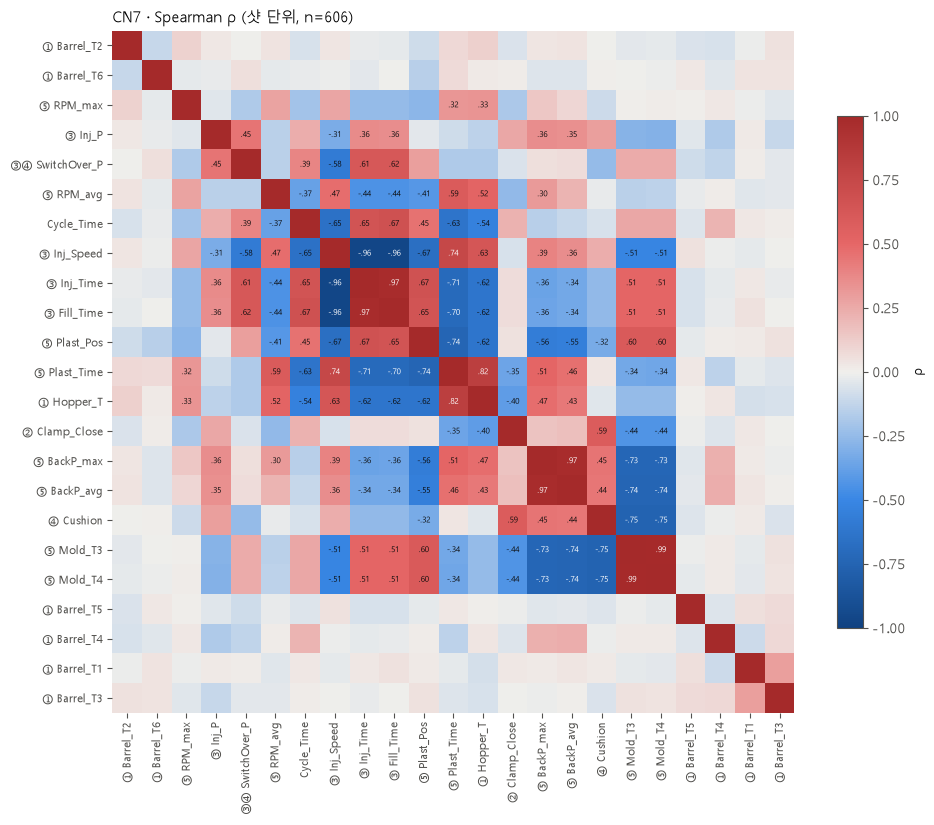

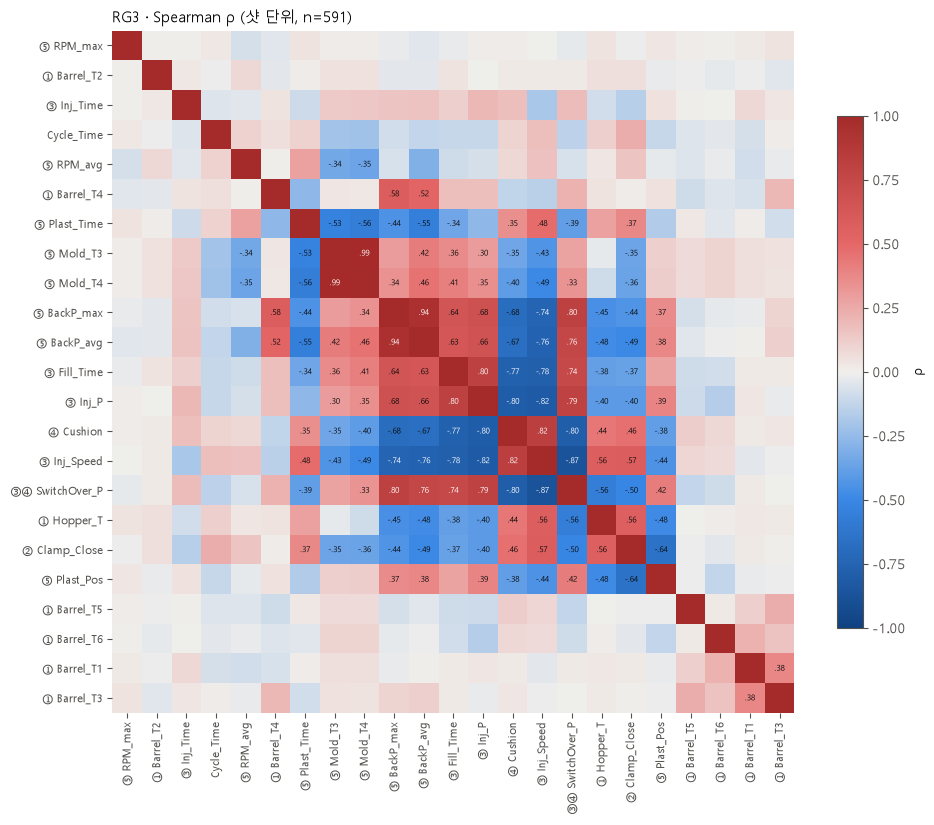

In [3]:
def corr_matrix(df, feats, method='spearman'):
    return df[feats].corr(method=method)

def cluster_order(C):
    D = 1 - C.abs().values
    np.fill_diagonal(D, 0)
    Z = linkage(squareform(D, checks=False), method='average')
    return [C.columns[i] for i in leaves_list(Z)], Z

def plot_heatmap(C, title, ax, annot_min=0.3):
    n = len(C)
    im = ax.imshow(C.values, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels([ABBR[c] for c in C.columns], rotation=90, fontsize=8)
    ax.set_yticklabels([ABBR[c] for c in C.index], fontsize=8)
    for i in range(n):
        for j in range(n):
            v = C.values[i, j]
            if i != j and abs(v) >= annot_min:
                ax.text(j, i, f'{v:.2f}'.replace('0.', '.'), ha='center', va='center', fontsize=6,
                        color='white' if abs(v) >= 0.7 else '#0b0b0b')
    ax.set_title(title, fontsize=11, loc='left')
    for s in ax.spines.values():
        s.set_visible(False)
    return im

CORR, ORDER = {}, {}
for p in PRODUCTS:
    C = corr_matrix(SHOTS[p], USE_FEATS[p], 'spearman')
    order, _ = cluster_order(C)
    CORR[p], ORDER[p] = C, order
    fig, ax = plt.subplots(figsize=(11, 9.5))
    im = plot_heatmap(C.loc[order, order], f'{p.upper()} · Spearman ρ (샷 단위, n={len(SHOTS[p])})', ax)
    fig.colorbar(im, ax=ax, shrink=0.7, label='ρ')
    savefig(fig, f'heatmap_spearman_{p}')
    plt.show()

### 3-1. Pearson vs Spearman 차이

두 값이 크게 다르면 **비선형 관계**이거나 **소수의 이상치**가 Pearson을 끌고 간 경우입니다. 이런 쌍은 산점도를 꼭 직접 봅니다.

In [4]:
def upper_pairs(C, name):
    m = np.triu(np.ones(C.shape, dtype=bool), k=1)
    s = C.where(m).stack()
    s.index.names = ['var1', 'var2']
    return s.rename(name)

diff_rows = []
for p in PRODUCTS:
    sp = upper_pairs(CORR[p], 'spearman')
    pe = upper_pairs(corr_matrix(SHOTS[p], USE_FEATS[p], 'pearson'), 'pearson')
    d = pd.concat([sp, pe], axis=1)
    d['diff'] = d['pearson'] - d['spearman']
    d = d[d['diff'].abs() >= 0.2].assign(product=p)
    diff_rows.append(d.reset_index())
pp_diff = pd.concat(diff_rows).sort_values('diff', key=np.abs, ascending=False)
print(f'|Pearson − Spearman| ≥ 0.2 인 쌍: {len(pp_diff)}개')
display(pp_diff.head(20).round(3))

|Pearson − Spearman| ≥ 0.2 인 쌍: 27개


,var1,var2,spearman,pearson,diff,product
7,Plasticizing_Time,Average_Back_Pressure,0.462,-0.101,-0.563,cn7
8,Plasticizing_Time,Hopper_Temperature,0.825,0.352,-0.472,cn7
4,Plasticizing_Time,Max_Injection_Pressure,-0.092,-0.470,-0.377,cn7
5,Plasticizing_Time,Max_Switch_Over_Pressure,-0.174,-0.511,-0.337,cn7
2,Plasticizing_Time,Plasticizing_Position,-0.738,-0.409,0.329,cn7
6,Plasticizing_Time,Max_Back_Pressure,0.514,0.187,-0.328,cn7
0,Filling_Time,Max_Switch_Over_Pressure,0.737,0.415,-0.323,rg3
18,Average_Screw_RPM,Max_Switch_Over_Pressure,-0.148,-0.463,-0.315,cn7
3,Max_Injection_Pressure,Max_Switch_Over_Pressure,0.791,0.482,-0.309,rg3
2,Max_Injection_Speed,Max_Switch_Over_Pressure,-0.869,-0.560,0.309,rg3


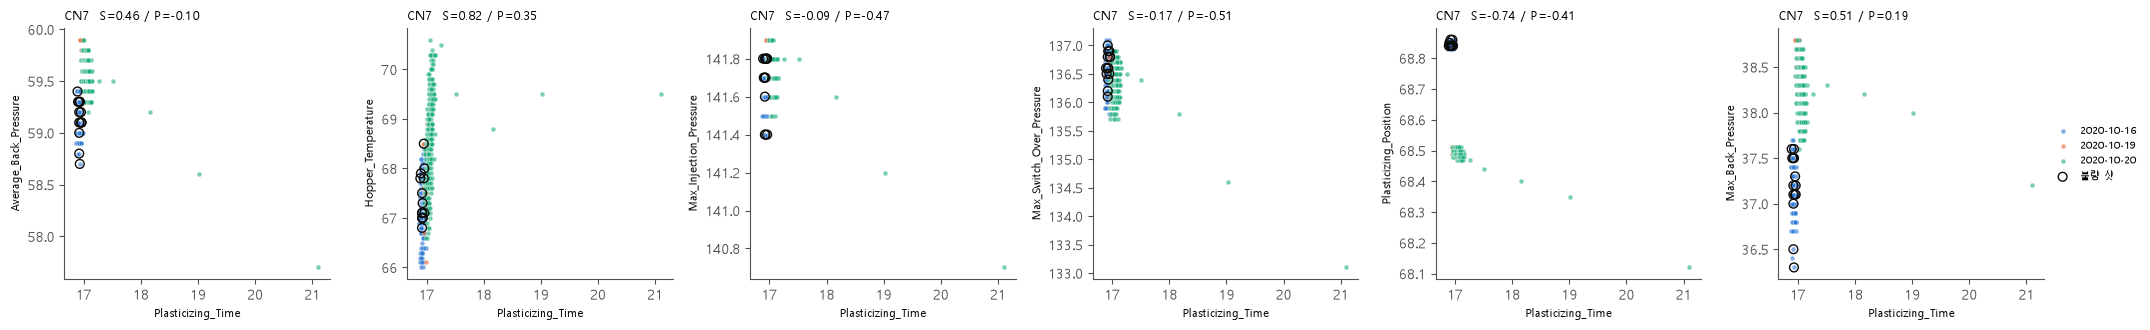

In [5]:
# 차이가 가장 큰 쌍 몇 개를 산점도로 확인 (점 = 샷, 색 = 날짜)
def scatter_by_date(s, x, y, ax, title=None):
    dates = sorted(s['ts_date'].unique())
    for k, d in enumerate(dates):
        g = s[s['ts_date'] == d]
        ax.scatter(g[x], g[y], s=12, alpha=0.6, color=CATEGORICAL[k % len(CATEGORICAL)],
                   edgecolor='white', linewidth=0.3, label=d)
    f = s[s['shot_fail'] == 1]
    ax.scatter(f[x], f[y], s=40, facecolor='none', edgecolor='#0b0b0b', linewidth=1.0, label='불량 샷')
    ax.set_xlabel(x, fontsize=8); ax.set_ylabel(y, fontsize=8)
    if title:
        ax.set_title(title, fontsize=9, loc='left')

top = pp_diff.head(6)
if len(top):
    fig, axes = plt.subplots(1, len(top), figsize=(3.6 * len(top), 3.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], top.iterrows()):
        scatter_by_date(SHOTS[r['product']], r['var1'], r['var2'], ax,
                        f"{r['product'].upper()}  S={r['spearman']:.2f} / P={r['pearson']:.2f}")
    axes[0][-1].legend(fontsize=7, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
    fig.tight_layout(); savefig(fig, 'pearson_vs_spearman_scatter'); plt.show()

## 4. 고상관 쌍과 변수 그룹

### 4-1. |ρ| ≥ `HIGH_CORR` 쌍 (두 제품 비교)

In [6]:
pairs = pd.concat([upper_pairs(CORR[p], p) for p in PRODUCTS], axis=1)
high = pairs[(pairs.abs() >= HIGH_CORR).any(axis=1)].copy()
high['같은 방향?'] = np.where(np.sign(high['cn7']) == np.sign(high['rg3']), '✅', '⚠️ 부호 다름')
high.loc[high[PRODUCTS].isna().any(axis=1), '같은 방향?'] = '한쪽 상수'
high = high.reindex(high[PRODUCTS].abs().max(axis=1).sort_values(ascending=False).index)
print(f'고상관 쌍 {len(high)}개 (둘 중 한 제품이라도 |ρ| ≥ {HIGH_CORR})')
display(high.round(3))

고상관 쌍 11개 (둘 중 한 제품이라도 |ρ| ≥ 0.8)


,,cn7,rg3,같은 방향?
var1,var2,,,
Mold_Temperature_3,Mold_Temperature_4,0.988,0.987,✅
Injection_Time,Filling_Time,0.971,0.113,✅
Max_Back_Pressure,Average_Back_Pressure,0.970,0.944,✅
Injection_Time,Max_Injection_Speed,-0.965,-0.194,✅
Filling_Time,Max_Injection_Speed,-0.964,-0.777,✅
Max_Injection_Speed,Max_Switch_Over_Pressure,-0.582,-0.869,✅
Plasticizing_Time,Hopper_Temperature,0.825,0.285,✅
Cushion_Position,Max_Injection_Speed,0.237,0.822,✅
Max_Injection_Speed,Max_Injection_Pressure,-0.313,-0.819,✅


### 4-2. 변수 그룹 (노션 3-2 표에 옮길 내용)

군집 트리를 거리 1 − `HIGH_CORR`에서 잘라, 서로 |ρ|가 평균적으로 높은 변수끼리 묶습니다.
**대표 변수**는 그룹 안 다른 변수와의 평균 |ρ|가 가장 높은 변수(가장 많이 대변하는 변수)입니다. 최종 선택은 공정적 의미를 보고 정합니다.

In [7]:
def variable_groups(C, thr=HIGH_CORR):
    _, Z = cluster_order(C)
    lab = fcluster(Z, t=1 - thr, criterion='distance')
    out = []
    for g in np.unique(lab):
        mem = [c for c, l in zip(C.columns, lab) if l == g]
        if len(mem) < 2:
            continue
        sub = C.loc[mem, mem].abs()
        vals = sub.values[np.triu_indices(len(mem), 1)]
        rep = sub.mean().idxmax()
        out.append({'변수 그룹': ', '.join(mem), '변수 수': len(mem),
                    '|ρ| 범위': f'{vals.min():.2f} ~ {vals.max():.2f}', '대표 후보': rep,
                    '물리적 이유': '', '설명됨?': '✅ / ❓ / ❌', '처리 (제거·통합·유지)': ''})
    return pd.DataFrame(out).sort_values('변수 수', ascending=False)

GROUPS = {}
for p in PRODUCTS:
    GROUPS[p] = variable_groups(CORR[p])
    print(f'==================== {p.upper()} ====================')
    display(GROUPS[p])

==================== CN7 ====================


,변수 그룹,변수 수,|ρ| 범위,대표 후보,물리적 이유,설명됨?,처리 (제거·통합·유지)
0,"Injection_Time, Filling_Time, Max_Injection_Speed",3,0.96 ~ 0.97,Injection_Time,,✅ / ❓ / ❌,
1,"Plasticizing_Time, Hopper_Temperature",2,0.82 ~ 0.82,Plasticizing_Time,,✅ / ❓ / ❌,
2,"Max_Back_Pressure, Average_Back_Pressure",2,0.97 ~ 0.97,Max_Back_Pressure,,✅ / ❓ / ❌,
3,"Mold_Temperature_3, Mold_Temperature_4",2,0.99 ~ 0.99,Mold_Temperature_3,,✅ / ❓ / ❌,


==================== RG3 ====================


,변수 그룹,변수 수,|ρ| 범위,대표 후보,물리적 이유,설명됨?,처리 (제거·통합·유지)
2,"Cushion_Position, Max_Injection_Speed, Max_Inj...",4,0.79 ~ 0.87,Max_Injection_Speed,,✅ / ❓ / ❌,
0,"Mold_Temperature_3, Mold_Temperature_4",2,0.99 ~ 0.99,Mold_Temperature_3,,✅ / ❓ / ❌,
1,"Max_Back_Pressure, Average_Back_Pressure",2,0.94 ~ 0.94,Max_Back_Pressure,,✅ / ❓ / ❌,


### 4-3. 다중공선성 (VIF)

VIF = 상관행렬 역행렬의 대각 성분. **10 이상이면** 다른 변수들로 거의 설명되는 변수라 선형 모델·계수 해석에서 문제가 됩니다 (트리 모델은 예측엔 영향이 적지만 중요도가 쪼개집니다).

In [8]:
def vif_table(s, feats):
    C = s[feats].corr(method='pearson').values
    inv = np.linalg.pinv(C)
    return pd.Series(np.diag(inv), index=feats)

vif = pd.DataFrame({p: vif_table(SHOTS[p], USE_FEATS[p]) for p in PRODUCTS})
vif = vif.reindex(vif.max(axis=1).sort_values(ascending=False).index)
display(vif.round(1).style.background_gradient(cmap='Reds', vmin=1, vmax=30).format('{:.1f}', na_rep='상수'))

,cn7,rg3
Mold_Temperature_4,663.1,96.4
Mold_Temperature_3,344.5,81.4
Plasticizing_Position,89.4,2.0
Max_Back_Pressure,51.0,27.1
Average_Back_Pressure,36.0,30.8
Injection_Time,34.8,2.5
Filling_Time,33.1,3.2
Max_Injection_Speed,10.8,7.9
Cushion_Position,3.6,7.9
Plasticizing_Time,6.9,2.2


## 5. 가설 A 검증 (정상 공정의 변수 관계)

Confluence **2. EDA 가설 > A** 표의 A1~A8을 수치로 확인합니다. **양품 샷만** 사용합니다 (불량 샷이 정상 관계를 흐리지 않도록).

판정 기준 (제안, 팀에서 조정 가능)
- **지지**: 예상 부호와 같고 |ρ| ≥ 0.3, p < 0.05
- **약함**: 부호는 같지만 |ρ| < 0.3 또는 유의하지 않음
- **기각**: 반대 부호이고 |ρ| ≥ 0.3, p < 0.05
- **판단 보류**: 변수가 상수라 계산 불가 등

A3는 속도의 영향을 빼고 온도와 압력의 관계를 봐야 해서 **편상관**(속도를 통제한 Spearman)으로 계산합니다.

In [9]:
def partial_spearman(df, x, y, z):
    # z를 통제한 x-y 순위 편상관: 순위 변환 → z로 선형 회귀 잔차 → 잔차끼리 Pearson
    r = df[[x, y] + z].rank()
    Zm = np.column_stack([np.ones(len(r)), r[z].values])
    res = lambda v: v - Zm @ np.linalg.lstsq(Zm, v, rcond=None)[0]
    return stats.pearsonr(res(r[x].values), res(r[y].values))

def verdict(rho, pval, sign):
    if rho is None or np.isnan(rho):
        return '판단 보류'
    if np.sign(rho) == sign and abs(rho) >= 0.3 and pval < 0.05:
        return '지지'
    if np.sign(rho) == -sign and abs(rho) >= 0.3 and pval < 0.05:
        return '기각'
    return '약함'

# (ID, 설명, x, y, 예상 부호, 통제변수)
HYP_A = [
    ('A1', '사출 속도↑ → 충전 시간↓', 'Max_Injection_Speed', 'Filling_Time', -1, None),
    ('A2', '사출 속도↑ → 사출 압력↑', 'Max_Injection_Speed', 'Max_Injection_Pressure', +1, None),
    ('A3', '(속도 통제) 배럴 온도↑ → 사출 압력↓', 'Barrel_mean', 'Max_Injection_Pressure', -1, ['Max_Injection_Speed']),
    ('A3', '(속도 통제) 금형 온도↑ → 사출 압력↓', 'Mold_mean', 'Max_Injection_Pressure', -1, ['Max_Injection_Speed']),
    ('A4', '충전 시간↑ → 사출 시간↑', 'Filling_Time', 'Injection_Time', +1, None),
    ('A5', '스크류 RPM↑ → 계량 시간↓', 'Average_Screw_RPM', 'Plasticizing_Time', -1, None),
    ('A5', '배압↑ → 계량 시간↑', 'Average_Back_Pressure', 'Plasticizing_Time', +1, None),
    ('A6', '계량 시간↑ → 사이클 시간↑', 'Plasticizing_Time', 'Cycle_Time', +1, None),
    ('A7', '금형 온도 센서 3·4 같이 움직임', 'Mold_Temperature_3', 'Mold_Temperature_4', +1, None),
    ('A8', '계량량↑ → 쿠션↑', 'Plasticizing_Position', 'Cushion_Position', +1, None),
]

def add_means(s):
    s = s.copy()
    s['Barrel_mean'] = s[[f'Barrel_Temperature_{i}' for i in range(1, 7)]].mean(axis=1)
    s['Mold_mean'] = s[['Mold_Temperature_3', 'Mold_Temperature_4']].mean(axis=1)
    return s

def within_day(s, cols):
    # 날짜별 중앙값을 빼서 운전 구간(날짜) 차이를 제거
    s = s.copy()
    s[cols] = s[cols] - s.groupby('ts_date')[cols].transform('median')
    return s

def test_pair(s, x, y, z):
    if s[x].nunique() < 2 or s[y].nunique() < 2:
        return np.nan, np.nan
    if z:
        r = partial_spearman(s, x, y, z)
    else:
        r = stats.spearmanr(s[x], s[y])
    return r[0], r[1]

rows = []
for p in PRODUCTS:
    s = add_means(SHOTS[p])
    s = s[s['shot_fail'] == 0]
    cols = USE_FEATS[p] + ['Barrel_mean', 'Mold_mean']
    sw = within_day(s, cols)
    for hid, desc, x, y, sign, z in HYP_A:
        rho, pv = test_pair(s, x, y, z)
        rho_w, pv_w = test_pair(sw, x, y, z)
        rows.append({'ID': hid, '가설': desc, 'product': p, 'ρ (전체)': rho, 'p': pv, '판정': verdict(rho, pv, sign),
                     'ρ (일자 내)': rho_w, '판정 (일자 내)': verdict(rho_w, pv_w, sign)})

# A7 배럴 온도 1~6: 쌍별 최소/중앙 ρ
for p in PRODUCTS:
    s = SHOTS[p][SHOTS[p]['shot_fail'] == 0]
    bt = [c for c in USE_FEATS[p] if c.startswith('Barrel_Temperature')]
    v = s[bt].corr('spearman').values[np.triu_indices(len(bt), 1)]
    rows.append({'ID': 'A7', '가설': f'배럴 온도 {len(bt)}개 같이 움직임 (쌍별 최소 ρ, 중앙 ρ={np.median(v):.2f})',
                 'product': p, 'ρ (전체)': v.min(), 'p': np.nan,
                 '판정': '지지' if v.min() >= 0.3 else ('약함' if v.min() >= 0 else '기각'),
                 'ρ (일자 내)': np.nan, '판정 (일자 내)': '-'})

hypA = pd.DataFrame(rows)
hypA_wide = hypA.pivot_table(index=['ID', '가설'], columns='product',
                             values=['ρ (전체)', '판정', 'ρ (일자 내)', '판정 (일자 내)'], aggfunc='first')
hypA_wide = hypA_wide.reindex(columns=['ρ (전체)', '판정', 'ρ (일자 내)', '판정 (일자 내)'], level=0)

def color_verdict(v):
    return {'지지': 'background-color:#d3f1a7', '기각': 'background-color:#fedec8',
            '약함': 'background-color:#f8e6a0', '판단 보류': 'background-color:#dcdfe4'}.get(v, '')
display(hypA_wide.style.format(lambda v: f'{v:.2f}' if isinstance(v, float) else v, na_rep='-')
        .map(color_verdict))

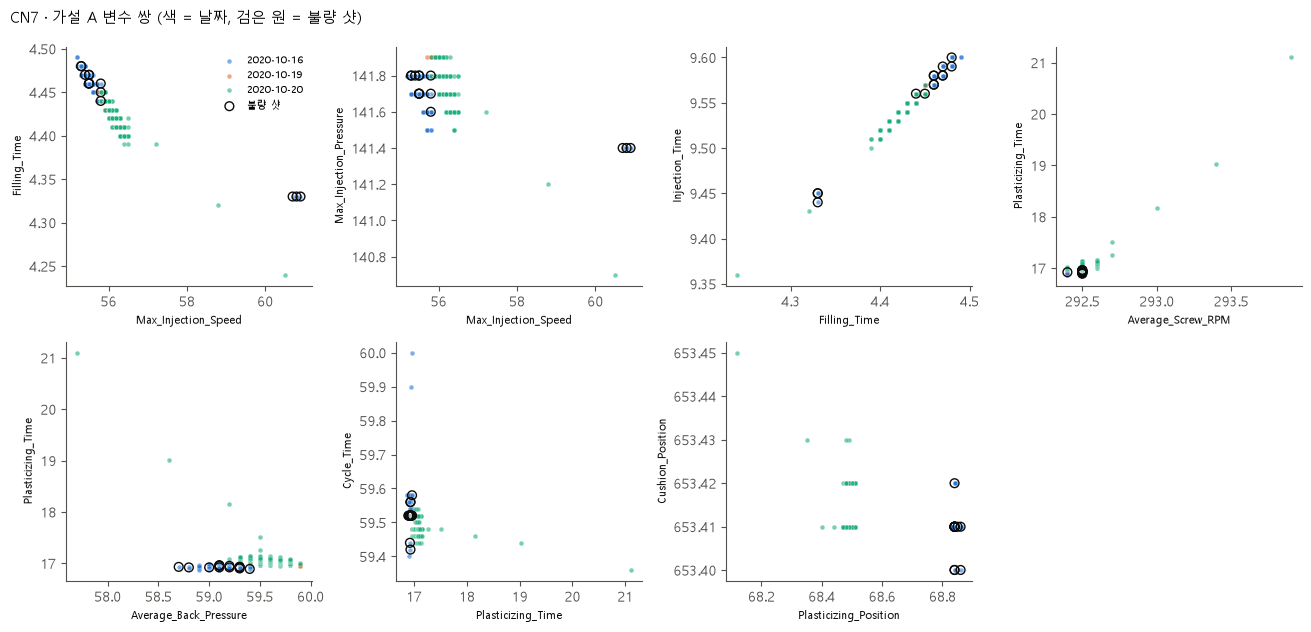

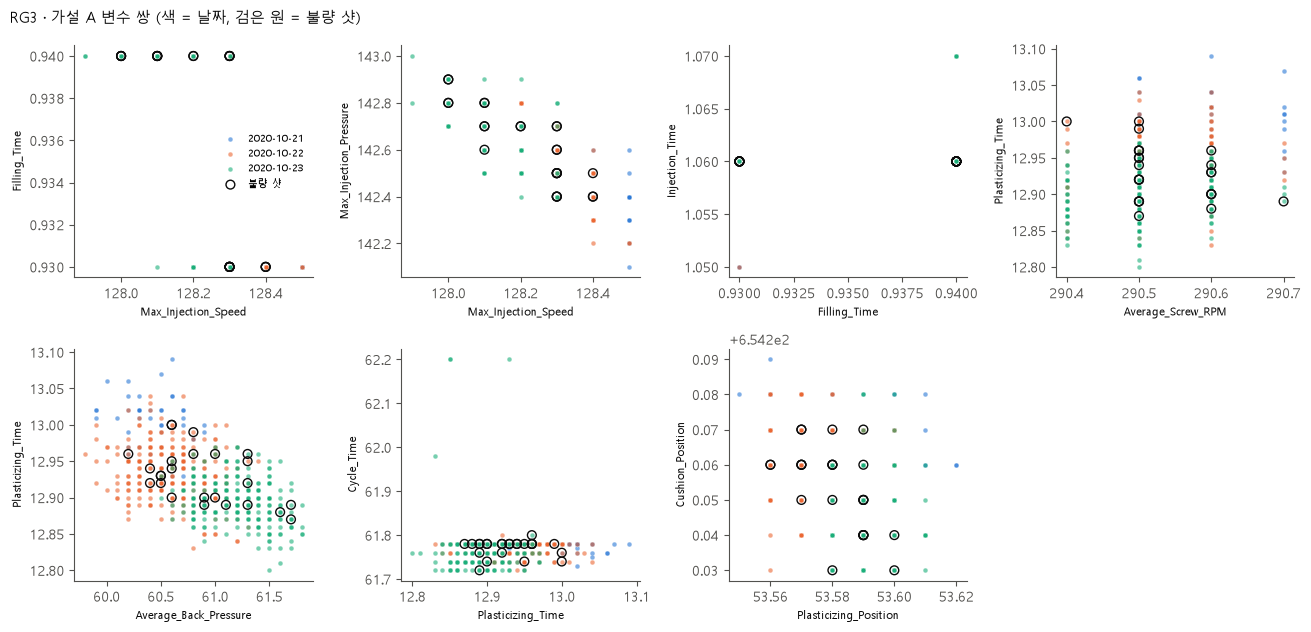

In [10]:
# 가설 A 쌍 산점도 (양품 + 불량 표시, 색 = 날짜) — 판정의 근거 그림
pairs_to_plot = [(h[2], h[3]) for h in HYP_A if h[5] is None and h[0] != 'A7']
for p in PRODUCTS:
    s = add_means(SHOTS[p])
    n = len(pairs_to_plot)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3.3 * ((n + 1) // 2), 6.4))
    for ax, (x, y) in zip(axes.flat, pairs_to_plot):
        scatter_by_date(s, x, y, ax)
    for ax in axes.flat[n:]:
        ax.axis('off')
    axes.flat[0].legend(fontsize=7, frameon=False)
    fig.suptitle(f'{p.upper()} · 가설 A 변수 쌍 (색 = 날짜, 검은 원 = 불량 샷)', x=0.01, ha='left', fontsize=11)
    fig.tight_layout(); savefig(fig, f'hypA_scatter_{p}'); plt.show()

## 6. 운전 구간 효과 (C2): 전체 상관 vs 일자 내 상관

**전체 상관은 높은데 일자 내 상관이 낮으면**, 두 변수가 샷마다 같이 움직인 게 아니라 **날짜(레시피·예열 상태)가 바뀔 때 통째로 같이 바뀐 것**입니다.
이런 쌍은 물리적 관계로 해석하면 안 되고, 날짜(운전 구간) 효과를 먼저 제거한 뒤 B 가설을 검증해야 합니다.

In [11]:
def regime_table(p):
    s = SHOTS[p]
    feats = USE_FEATS[p]
    sw = within_day(s, feats)
    overall = upper_pairs(s[feats].corr('spearman'), '전체 ρ')
    wd = upper_pairs(sw[feats].corr('spearman'), '일자 내 ρ')
    t = pd.concat([overall, wd], axis=1)
    t['차이(전체−일자내)'] = t['전체 ρ'].abs() - t['일자 내 ρ'].abs()
    return t

REGIME = {p: regime_table(p) for p in PRODUCTS}
for p in PRODUCTS:
    t = REGIME[p]
    shown = t[t['전체 ρ'].abs() >= 0.5].sort_values('차이(전체−일자내)', ascending=False)
    print(f'==================== {p.upper()} : 전체 |ρ| ≥ 0.5 쌍 {len(shown)}개 ====================')
    print(f"그중 일자 내 |ρ| < 0.3 (운전 구간 효과로 의심): {int((shown['일자 내 ρ'].abs() < 0.3).sum())}개")
    display(shown.head(15).round(2))

==================== CN7 : 전체 |ρ| ≥ 0.5 쌍 45개 ====================
그중 일자 내 |ρ| < 0.3 (운전 구간 효과로 의심): 28개


전체 ρ  일자 내 ρ  차이(전체−일자내)
var1                  var2                                           
Plasticizing_Position Max_Injection_Speed   -0.67   -0.01        0.66
Filling_Time          Plasticizing_Position  0.65    0.05        0.60
Injection_Time        Plasticizing_Position  0.67    0.07        0.59
Max_Back_Pressure     Mold_Temperature_3    -0.73   -0.16        0.58
                      Mold_Temperature_4    -0.73   -0.16        0.57
Injection_Time        Plasticizing_Time     -0.71   -0.14        0.57
Filling_Time          Plasticizing_Time     -0.70   -0.14        0.57
Average_Back_Pressure Mold_Temperature_3    -0.74   -0.18        0.56
                      Mold_Temperature_4    -0.74   -0.18        0.56
Plasticizing_Time     Max_Injection_Speed    0.74    0.20        0.54
                      Plasticizing_Position -0.74   -0.20        0.53
Plasticizing_Position Hopper_Temperature    -0.62   -0.12        0.51
Max_Injection_Speed   Hopper_Temperature     0.63    0.13        0.50
Injection_Time        Hopper_Temperature    -0.62   -0.13        0.49
Filling_Time          Hopper_Temperature    -0.62   -0.13        0.49

==================== RG3 : 전체 |ρ| ≥ 0.5 쌍 33개 ====================
그중 일자 내 |ρ| < 0.3 (운전 구간 효과로 의심): 8개


전체 ρ  일자 내 ρ  차이(전체−일자내)
var1                     var2                                              
Max_Injection_Speed      Hopper_Temperature        0.56    0.00        0.56
Clamp_Close_Time         Max_Injection_Speed       0.57    0.03        0.54
                         Max_Switch_Over_Pressure -0.50   -0.01        0.50
Max_Switch_Over_Pressure Hopper_Temperature       -0.56   -0.08        0.47
Clamp_Close_Time         Hopper_Temperature        0.56   -0.11        0.45
Filling_Time             Max_Injection_Pressure    0.80    0.38        0.42
Plasticizing_Time        Average_Back_Pressure    -0.55   -0.25        0.29
Clamp_Close_Time         Plasticizing_Position    -0.64   -0.36        0.29
Max_Injection_Speed      Average_Back_Pressure    -0.76   -0.48        0.28
Max_Injection_Pressure   Average_Back_Pressure     0.66    0.39        0.28
Filling_Time             Max_Back_Pressure         0.64    0.38        0.27
Plasticizing_Time        Mold_Temperature_4       -0.56   -0.30        0.26
Filling_Time             Average_Back_Pressure     0.63    0.40        0.23
Plasticizing_Time        Mold_Temperature_3       -0.53   -0.29        0.23
Cushion_Position         Average_Back_Pressure    -0.67   -0.45        0.21

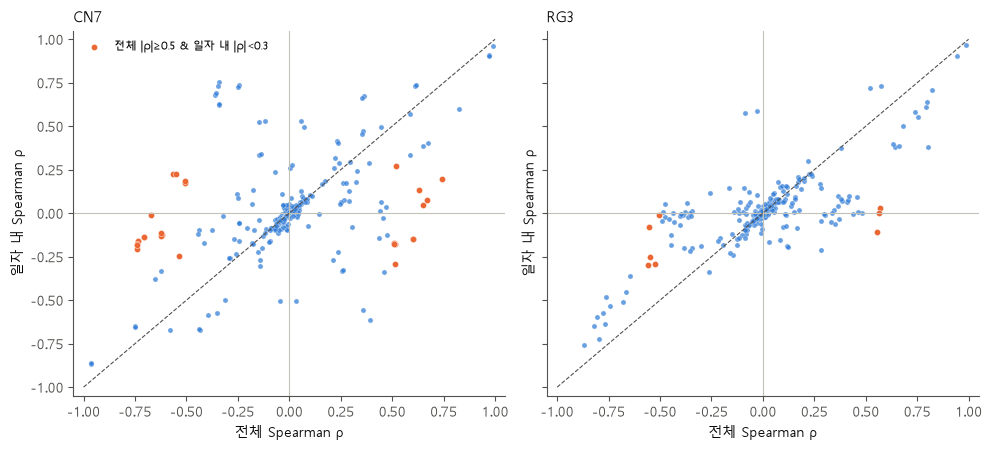

In [12]:
# 전체 ρ vs 일자 내 ρ 산점도: 대각선에서 아래로 멀수록 날짜 효과가 큰 쌍
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, p in zip(axes, PRODUCTS):
    t = REGIME[p].dropna()
    ax.axhline(0, color='#c3c2b7', lw=0.8); ax.axvline(0, color='#c3c2b7', lw=0.8)
    ax.plot([-1, 1], [-1, 1], color='#52514e', lw=0.8, ls='--')
    ax.scatter(t['전체 ρ'], t['일자 내 ρ'], s=14, color=CATEGORICAL[0], alpha=0.7, edgecolor='white', linewidth=0.3)
    big = t[(t['전체 ρ'].abs() >= 0.5) & (t['일자 내 ρ'].abs() < 0.3)]
    ax.scatter(big['전체 ρ'], big['일자 내 ρ'], s=20, color=CATEGORICAL[1], edgecolor='white', linewidth=0.3,
               label='전체 |ρ|≥0.5 & 일자 내 |ρ|<0.3')
    ax.set_title(f'{p.upper()}', loc='left', fontsize=11)
    ax.set_xlabel('전체 Spearman ρ'); ax.set_ylabel('일자 내 Spearman ρ')
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
axes[0].legend(fontsize=8, frameon=False, loc='upper left')
fig.tight_layout(); savefig(fig, 'regime_overall_vs_withinday'); plt.show()

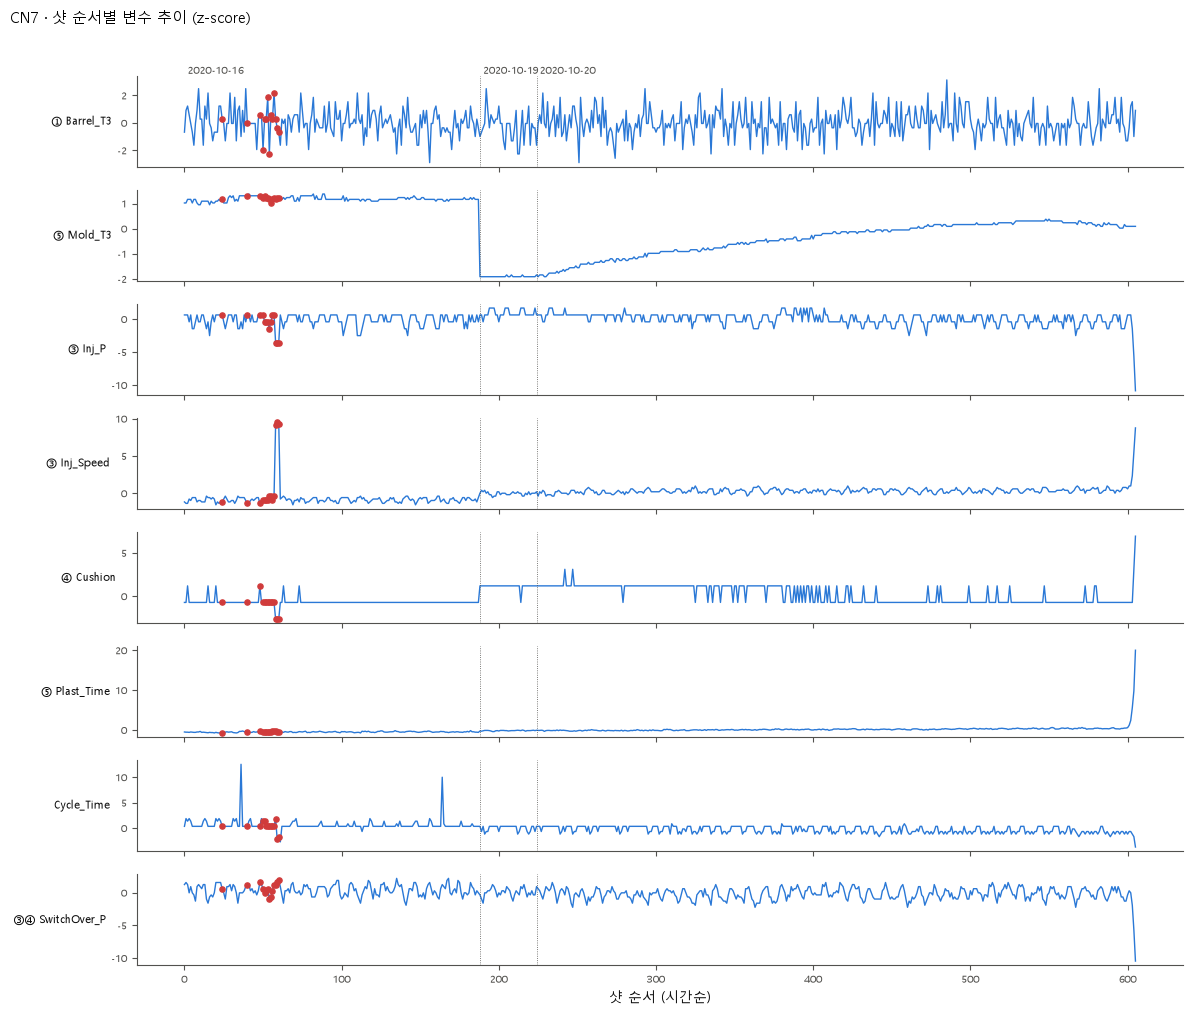

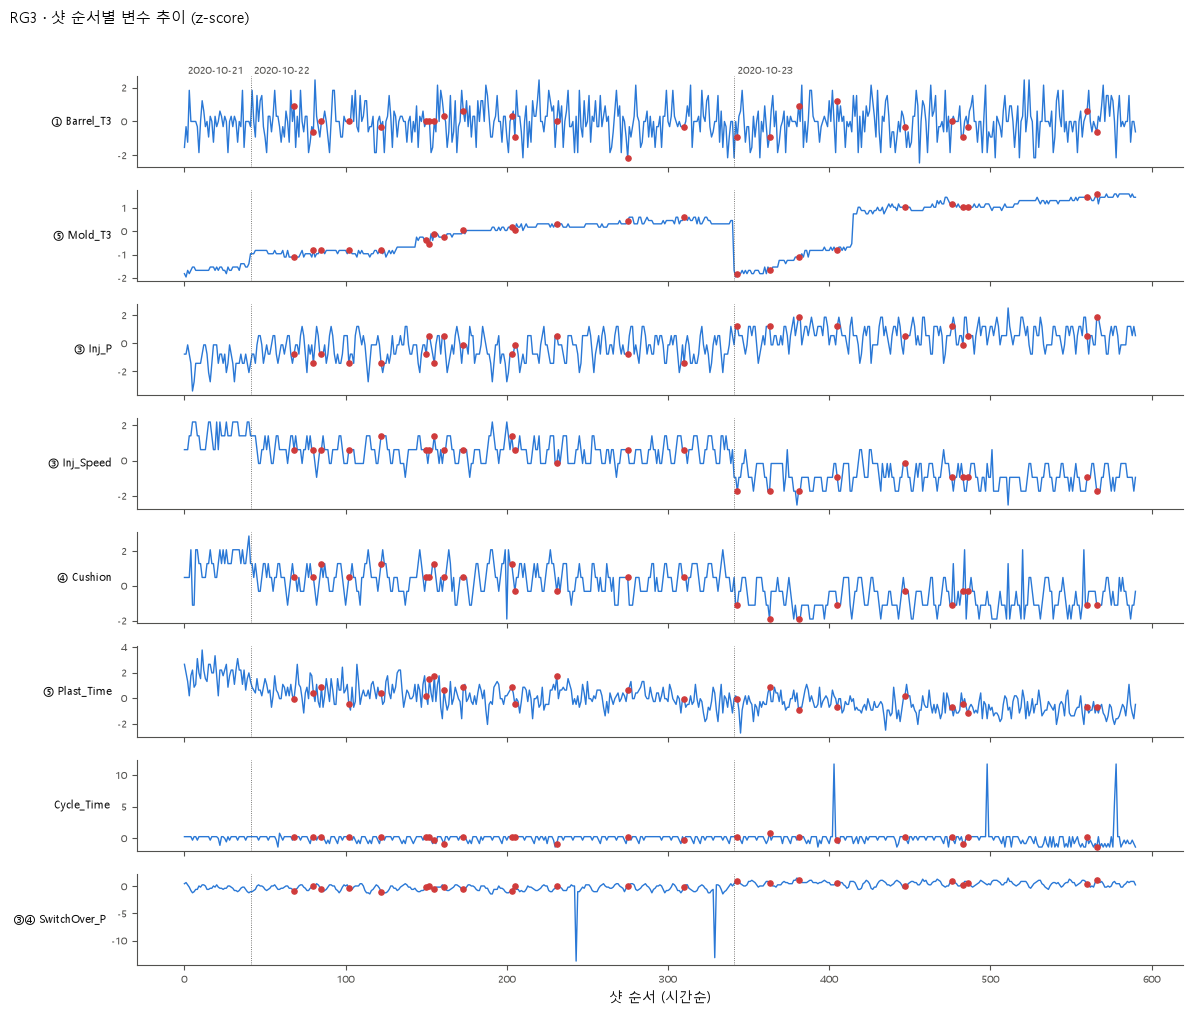

In [13]:
# 샷 순서에 따른 주요 변수 추이 (표준화, 날짜 경계 = 세로선, 빨간 점 = 불량 샷)
KEY_VARS = ['Barrel_Temperature_3', 'Mold_Temperature_3', 'Max_Injection_Pressure', 'Max_Injection_Speed',
            'Cushion_Position', 'Plasticizing_Time', 'Cycle_Time', 'Max_Switch_Over_Pressure']
for p in PRODUCTS:
    s = SHOTS[p]
    vars_ = [v for v in KEY_VARS if v in USE_FEATS[p]]
    fig, axes = plt.subplots(len(vars_), 1, figsize=(12, 1.25 * len(vars_)), sharex=True)
    bounds = s.groupby('ts_date')['shot_order'].min().values[1:]
    for ax, v in zip(axes, vars_):
        z = (s[v] - s[v].mean()) / (s[v].std() or 1)
        ax.plot(s['shot_order'], z, lw=1, color=CATEGORICAL[0])
        f = s['shot_fail'] == 1
        ax.scatter(s.loc[f, 'shot_order'], z[f], s=14, color=FAIL_COLOR, zorder=3)
        for b in bounds:
            ax.axvline(b, color='#52514e', lw=0.6, ls=':')
        ax.set_ylabel(ABBR[v], rotation=0, ha='right', va='center', fontsize=8)
        ax.tick_params(labelsize=7)
    for d, x0 in s.groupby('ts_date')['shot_order'].min().items():
        axes[0].text(x0 + 2, axes[0].get_ylim()[1], d, fontsize=7, va='bottom', color='#52514e')
    axes[-1].set_xlabel('샷 순서 (시간순)')
    fig.suptitle(f'{p.upper()} · 샷 순서별 변수 추이 (z-score)', x=0.01, ha='left', fontsize=11, y=1.01)
    fig.tight_layout(); savefig(fig, f'trend_{p}'); plt.show()

## 7. 불량과의 관계 (미리보기)

B 가설 검증 전에 변수별로 불량 샷과 양품 샷이 얼마나 다른지 훑어봅니다.
불량 샷이 적어서(CN7 14, RG3 25) **p-value보다 효과 크기**를 봅니다.

- **Cliff's δ**: 불량 샷 값이 양품보다 클 확률 − 작을 확률 (−1~1). |δ| ≥ 0.33 중간, ≥ 0.47 큼
- **일자 내 δ**: 날짜별 중앙값을 뺀 값으로 다시 계산. 전체 δ만 크고 일자 내 δ가 작으면 **불량이 특정 날짜에 몰려 생긴 착시**일 수 있음 (C3)

In [14]:
def cliffs_delta(a, b):
    # a = 불량, b = 양품
    u = stats.mannwhitneyu(a, b, alternative='two-sided')
    return 2 * u.statistic / (len(a) * len(b)) - 1, u.pvalue

def target_table(p):
    s = SHOTS[p]
    sw = within_day(s, USE_FEATS[p])
    out = []
    for v in USE_FEATS[p]:
        f, g = s['shot_fail'] == 1, s['shot_fail'] == 0
        d, pv = cliffs_delta(s.loc[f, v], s.loc[g, v])
        dw, pvw = cliffs_delta(sw.loc[f, v], sw.loc[g, v])
        out.append({'변수': v, 'δ': d, 'p': pv, '일자 내 δ': dw, '일자 내 p': pvw})
    return pd.DataFrame(out).set_index('변수')

TARGET = {p: target_table(p) for p in PRODUCTS}
tt = pd.concat({p: TARGET[p] for p in PRODUCTS}, axis=1)
tt = tt.reindex(tt.xs('δ', axis=1, level=1).abs().max(axis=1).sort_values(ascending=False).index)
display(tt.style.format('{:.3f}', na_rep='-')
        .background_gradient(cmap=DIVERGING, vmin=-1, vmax=1, subset=[(p, c) for p in PRODUCTS for c in ['δ', '일자 내 δ']]))

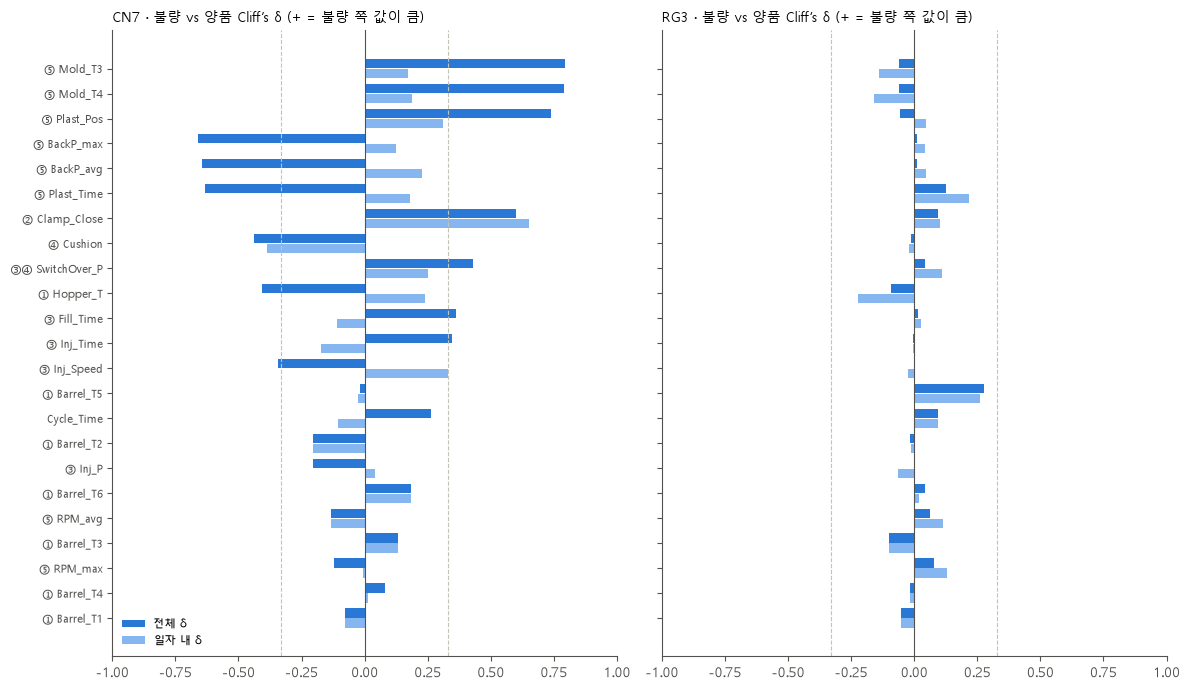

In [15]:
# δ 막대: 전체(진한 색) vs 일자 내(옅은 색)
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
order = tt.index[::-1]
y = np.arange(len(order))
for ax, p in zip(axes, PRODUCTS):
    t = TARGET[p].reindex(order)
    ax.barh(y + 0.2, t['δ'], height=0.38, color=CATEGORICAL[0], label='전체 δ')
    ax.barh(y - 0.2, t['일자 내 δ'], height=0.38, color='#86b6ef', label='일자 내 δ')
    for x in (-0.33, 0.33):
        ax.axvline(x, color='#c3c2b7', lw=0.8, ls='--')
    ax.axvline(0, color='#52514e', lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels([ABBR[v] for v in order], fontsize=8)
    ax.set_xlim(-1, 1); ax.set_title(f'{p.upper()} · 불량 vs 양품 Cliff’s δ (+ = 불량 쪽 값이 큼)', loc='left', fontsize=10)
axes[0].legend(frameon=False, fontsize=8, loc='lower left')
fig.tight_layout(); savefig(fig, 'target_cliffs_delta'); plt.show()

## 8. unlabeled에서도 상관 구조가 유지되는가 (C4)

unlabeled는 기간이 훨씬 길어서 표본이 많습니다. labeled에서 본 상관이 **unlabeled에서도 비슷하면** 안정적인 관계, **크게 다르면** labeled 기간만의 특성(또는 분포 차이)입니다.
준지도 학습에서 pseudo-label을 붙일 때 이 차이가 편향의 원인이 될 수 있습니다.

- unlabeled도 같은 `TimeStamp`의 LH·RH를 한 샷으로 합칩니다.

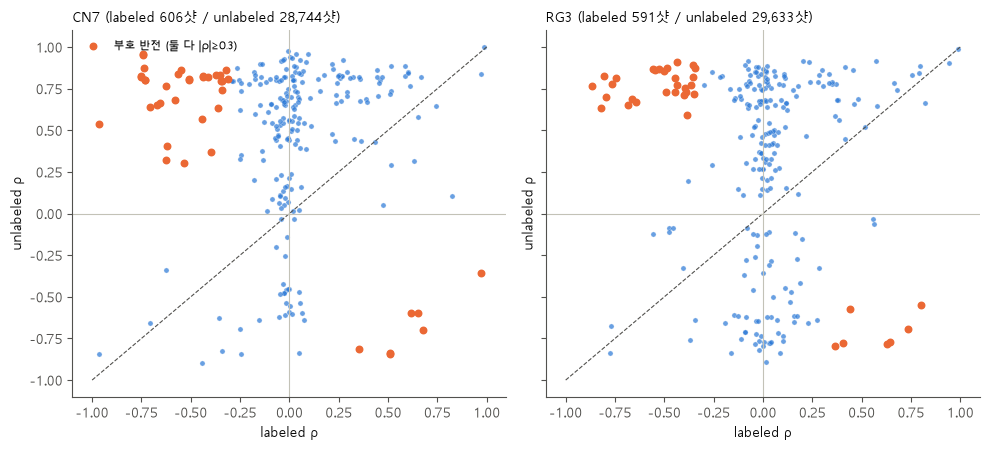

==================== CN7 : labeled ↔ unlabeled 차이가 큰 쌍 ====================


labeled ρ  unlabeled ρ    차이
var1                  var2                                               
Average_Back_Pressure Mold_Temperature_3         -0.74         0.96  1.70
                      Mold_Temperature_4         -0.74         0.95  1.69
Plasticizing_Time     Plasticizing_Position      -0.74         0.87  1.61
Cushion_Position      Mold_Temperature_4         -0.75         0.83  1.58
                      Mold_Temperature_3         -0.75         0.82  1.57
Max_Back_Pressure     Mold_Temperature_3         -0.73         0.80  1.54
                      Mold_Temperature_4         -0.73         0.80  1.54
Injection_Time        Max_Injection_Speed        -0.96         0.53  1.50
Plasticizing_Position Average_Back_Pressure      -0.55         0.86  1.41
                      Max_Back_Pressure          -0.56         0.83  1.40

==================== RG3 : labeled ↔ unlabeled 차이가 큰 쌍 ====================


labeled ρ  unlabeled ρ    차이
var1                var2                                                  
Max_Injection_Speed Max_Switch_Over_Pressure      -0.87         0.77  1.64
Cushion_Position    Max_Injection_Pressure        -0.80         0.83  1.63
Max_Injection_Speed Max_Back_Pressure             -0.74         0.81  1.55
                    Average_Back_Pressure         -0.76         0.78  1.54
Cushion_Position    Max_Switch_Over_Pressure      -0.80         0.70  1.49
Max_Injection_Speed Max_Injection_Pressure        -0.82         0.63  1.45
Filling_Time        Max_Switch_Over_Pressure       0.74        -0.69 -1.43
Plasticizing_Time   Mold_Temperature_4            -0.56         0.87  1.43
Filling_Time        Average_Back_Pressure          0.63        -0.78 -1.42
                    Max_Back_Pressure              0.64        -0.77 -1.42

In [16]:
if USE_UNLABELED:
    UCORR, UN = {}, {}
    for p in PRODUCTS:
        U = pd.read_csv(os.path.join(LINKED_DIR, f'linked_unlabeled_{p}.csv'), parse_dates=['TimeStamp'])
        U = U.rename(columns={f'{c}_raw': c for c in FEATURES}).drop_duplicates('TimeStamp')
        feats = [c for c in USE_FEATS[p] if U[c].nunique() > 1]
        UCORR[p], UN[p] = U[feats].corr('spearman'), len(U)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
    STAB = {}
    for ax, p in zip(axes, PRODUCTS):
        t = pd.concat([upper_pairs(CORR[p], 'labeled ρ'), upper_pairs(UCORR[p], 'unlabeled ρ')], axis=1).dropna()
        t['차이'] = t['unlabeled ρ'] - t['labeled ρ']
        STAB[p] = t
        ax.plot([-1, 1], [-1, 1], color='#52514e', lw=0.8, ls='--')
        ax.axhline(0, color='#c3c2b7', lw=0.8); ax.axvline(0, color='#c3c2b7', lw=0.8)
        ax.scatter(t['labeled ρ'], t['unlabeled ρ'], s=14, color=CATEGORICAL[0], alpha=0.7, edgecolor='white', linewidth=0.3)
        flip = t[(np.sign(t['labeled ρ']) != np.sign(t['unlabeled ρ'])) & (t[['labeled ρ', 'unlabeled ρ']].abs().min(axis=1) >= 0.3)]
        ax.scatter(flip['labeled ρ'], flip['unlabeled ρ'], s=22, color=CATEGORICAL[1], label='부호 반전 (둘 다 |ρ|≥0.3)')
        ax.set_title(f'{p.upper()} (labeled {len(SHOTS[p])}샷 / unlabeled {UN[p]:,}샷)', loc='left', fontsize=10)
        ax.set_xlabel('labeled ρ'); ax.set_ylabel('unlabeled ρ')
    axes[0].legend(frameon=False, fontsize=8, loc='upper left')
    fig.tight_layout(); savefig(fig, 'stability_labeled_vs_unlabeled'); plt.show()

    for p in PRODUCTS:
        print(f'==================== {p.upper()} : labeled ↔ unlabeled 차이가 큰 쌍 ====================')
        display(STAB[p].sort_values('차이', key=np.abs, ascending=False).head(10).round(2))

## 9. 저장 + 기록용 요약

In [18]:
for p in PRODUCTS:
    CORR[p].to_csv(os.path.join(OUT_DIR, f'spearman_{p}.csv'), encoding='utf-8-sig')
    GROUPS[p].to_csv(os.path.join(OUT_DIR, f'groups_{p}.csv'), index=False, encoding='utf-8-sig')
    REGIME[p].to_csv(os.path.join(OUT_DIR, f'regime_{p}.csv'), encoding='utf-8-sig')
high.to_csv(os.path.join(OUT_DIR, 'high_corr_pairs.csv'), encoding='utf-8-sig')
vif.to_csv(os.path.join(OUT_DIR, 'vif.csv'), encoding='utf-8-sig')
hypA.to_csv(os.path.join(OUT_DIR, 'hypothesis_A.csv'), index=False, encoding='utf-8-sig')
tt.to_csv(os.path.join(OUT_DIR, 'target_cliffs_delta.csv'), encoding='utf-8-sig')
print('저장 위치:', os.path.abspath(OUT_DIR), '/', os.path.abspath(FIG_DIR))

# Confluence 4장 '가설 검증 결과' 표에 옮기기 쉬운 형태
summary = hypA.groupby(['ID', 'product'])['판정'].agg(lambda s: ' / '.join(s)).unstack()
print('\n[가설 A 판정 요약]')
print(summary.to_markdown() if hasattr(summary, 'to_markdown') else summary.to_string())

저장 위치: c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\outputs\corr / c:\Users\한국전파진흥협회\OneDrive\바탕 화면\taein\스마트팩토리\KAMP 대회\2026년 경진대회\KAMP-IMM\notebooks\figures\corr

[가설 A 판정 요약]


ImportError: `Import tabulate` failed.  Use pip or conda to install the tabulate package.

## 10. 해석 메모 (실행 후 작성)

| 항목 | CN7 | RG3 |
|---|---|---|
| 함께 움직이는 변수 그룹 (4-2) | | |
| 제거·통합할 변수 후보 (VIF, 그룹) | | |
| 가설 A 중 지지 / 기각 | | |
| 운전 구간 효과로 의심되는 쌍 (6장) | | |
| 불량과 차이가 큰 변수 (7장, 일자 내 기준) | | |
| labeled ↔ unlabeled 상관 차이 (8장) | | |

**다음 단계 체크**
- [ ] 4-2 그룹의 '물리적 이유' 채워서 노션 3-2 표에 옮기기
- [ ] 가설 A 판정을 Confluence 4장 표에 반영
- [ ] 6장에서 날짜 효과가 큰 것으로 나온 변수는 B 가설 검증 시 **일자 내 값**으로 보기